## 2.1 Exploratory Data Analysis (EDA)

1. Dataset Overview

- Load cleaned file 
- Display its shape, column name, dtype 

2. Summary Statistics

- Summarize numeric features e.g. sleep duration, stress levels, physical activity such as daily steps taken
- Use the results to interpret and draw conclusions about the range and identify possible anomaly or unusal outliers 

3. Sleep Quality Classes 
- Count how many records are classified as low,medium, and high quality
- A bar chart will be used to visualize frequency in each category 

4. Visualizing Feature Distributions

5. Correlation Heatmap 

6. Assessing Sleep Quality against other features

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 



In [2]:
sns.set_style("whitegrid")

labels = {"age": "Age (years)", "daily_steps": "Daily steps",
          "heart_rate": "Resting heart rate (bpm)",
          "physical_activity_level": "Physical activity (min/day)",
          "sleep_duration": "Sleep duration (hours)", "stress_level": "Stress level (1-10)",
          "quality_of_sleep": "Sleep quality (1-10)",
          "gender_male": "Gender (male = 1)", "bmi_order": "BMI category (ordered)"}

FIG= "../figures"
TARGET = "quality_of_sleep"
CLASS = "sleep_quality_class"
class_order= ["low", "medium", "high"]
class_colors= ["#d9534f", "#f0ad4e", "#5cb85c"]
num_cols = ["age", "daily_steps", "heart_rate", "physical_activity_level", "sleep_duration", "stress_level"]

1. Dataset Overview 

In [3]:
df = pd.read_csv("../data/processed/merged_clean_v1.csv")
print("Shape:", df.shape)
df.head()

Shape: (2091, 11)


,age,bmi_category,daily_steps,gender,heart_rate,physical_activity_level,quality_of_sleep,sleep_duration,stress_level,source,sleep_quality_class
0,27.0,overweight,4200.0,male,77.0,42.0,6.0,6.1,6.0,dataset1,medium
1,28.0,normal,10000.0,male,75.0,60.0,6.0,6.2,8.0,dataset1,medium
2,28.0,obese,3000.0,male,85.0,30.0,4.0,5.9,8.0,dataset1,low
3,29.0,obese,3500.0,male,82.0,40.0,6.0,6.3,7.0,dataset1,medium
4,29.0,normal,8000.0,male,70.0,75.0,7.0,7.8,6.0,dataset1,medium


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2091 entries, 0 to 2090
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      2091 non-null   float64
 1   bmi_category             2091 non-null   str    
 2   daily_steps              2091 non-null   float64
 3   gender                   2091 non-null   str    
 4   heart_rate               2091 non-null   float64
 5   physical_activity_level  2091 non-null   float64
 6   quality_of_sleep         2091 non-null   float64
 7   sleep_duration           2091 non-null   float64
 8   stress_level             2028 non-null   float64
 9   source                   2091 non-null   str    
 10  sleep_quality_class      2091 non-null   str    
dtypes: float64(7), str(4)
memory usage: 179.8 KB


In [5]:
print("Missing values per column:")
print(df.isna().sum())
print()
print("Rows from each dataset: ")
print(df['source'].value_counts())

Missing values per column:
age                         0
bmi_category                0
daily_steps                 0
gender                      0
heart_rate                  0
physical_activity_level     0
quality_of_sleep            0
sleep_duration              0
stress_level               63
source                      0
sleep_quality_class         0
dtype: int64

Rows from each dataset: 
source
dataset2    1985
dataset1     106
Name: count, dtype: int64


Based on the output results, the clean and processed dataset contains 2091 rows. Only stress_level feature has missing values, namely 63 rows, which contributes to approximately 3%. The missing rows in both the raw versions of the dataset were filled with the training median when building the model. 

2. Generating Summary Statistics

In [6]:
df[num_cols +[TARGET]].describe().round(2)

,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level,quality_of_sleep
count,2091.00,2091.00,2091.00,2091.00,2091.00,2028.00,2091.00
mean,45.58,6861.04,71.64,60.94,6.89,4.94,7.04
std,14.10,3537.90,6.59,28.98,1.28,2.01,1.39
min,18.00,1000.00,52.00,0.00,4.00,1.00,2.20
25%,35.50,4200.00,67.00,41.10,6.00,3.50,6.00
50%,45.00,6782.00,72.00,60.50,6.90,4.90,7.10
75%,55.00,9163.50,76.00,79.90,7.80,6.40,8.00
max,80.00,19186.00,93.00,162.90,9.50,10.00,10.00


In [7]:
# Count outliers with the IQR rule (more than 1.5 * IQR outside the quartiles)
for col in num_cols + [TARGET]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, ":", len(outliers), "outliers")

age : 0 outliers
daily_steps : 8 outliers
heart_rate : 9 outliers
physical_activity_level : 11 outliers
sleep_duration : 0 outliers
stress_level : 0 outliers
quality_of_sleep : 4 outliers


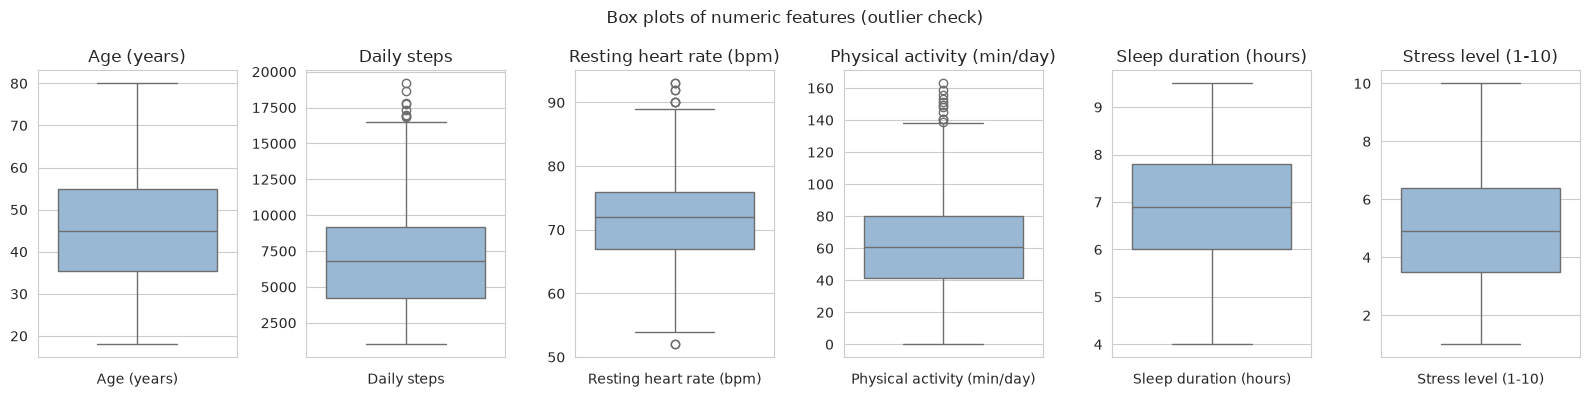

In [8]:
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for i in range(6):
    col = num_cols[i]
    sns.boxplot(y=df[col], ax=axes[i], color="#8fb8de")
    axes[i].set_title(labels[col])
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("")
plt.suptitle("Box plots of numeric features (outlier check)")
plt.tight_layout()
plt.savefig(FIG + "/eda_01_boxplots_outliers.png")
plt.show()

3. Sleep Quality Classes 

In [9]:
counts = df[CLASS].value_counts()[class_order]
percent = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": percent}))

                     count  percent
sleep_quality_class                
low                    451     21.6
medium                1078     51.6
high                   562     26.9


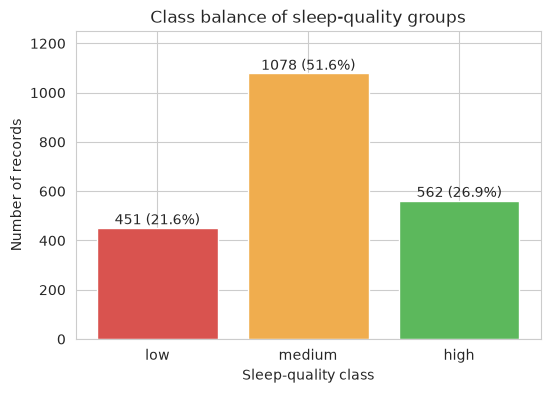

In [10]:
plt.figure(figsize=(6, 4))
plt.bar(class_order, counts, color=class_colors)
for i in range(3):
    plt.text(i, counts.iloc[i] + 15, str(counts.iloc[i]) + " (" + str(percent.iloc[i]) + "%)", ha="center")
plt.title("Class balance of sleep-quality groups")
plt.xlabel("Sleep-quality class")
plt.ylabel("Number of records")
plt.ylim(0, 1250)
plt.savefig(FIG + "/eda_02_class_balance.png")
plt.show()

4. Visualizing Feature Distributions 

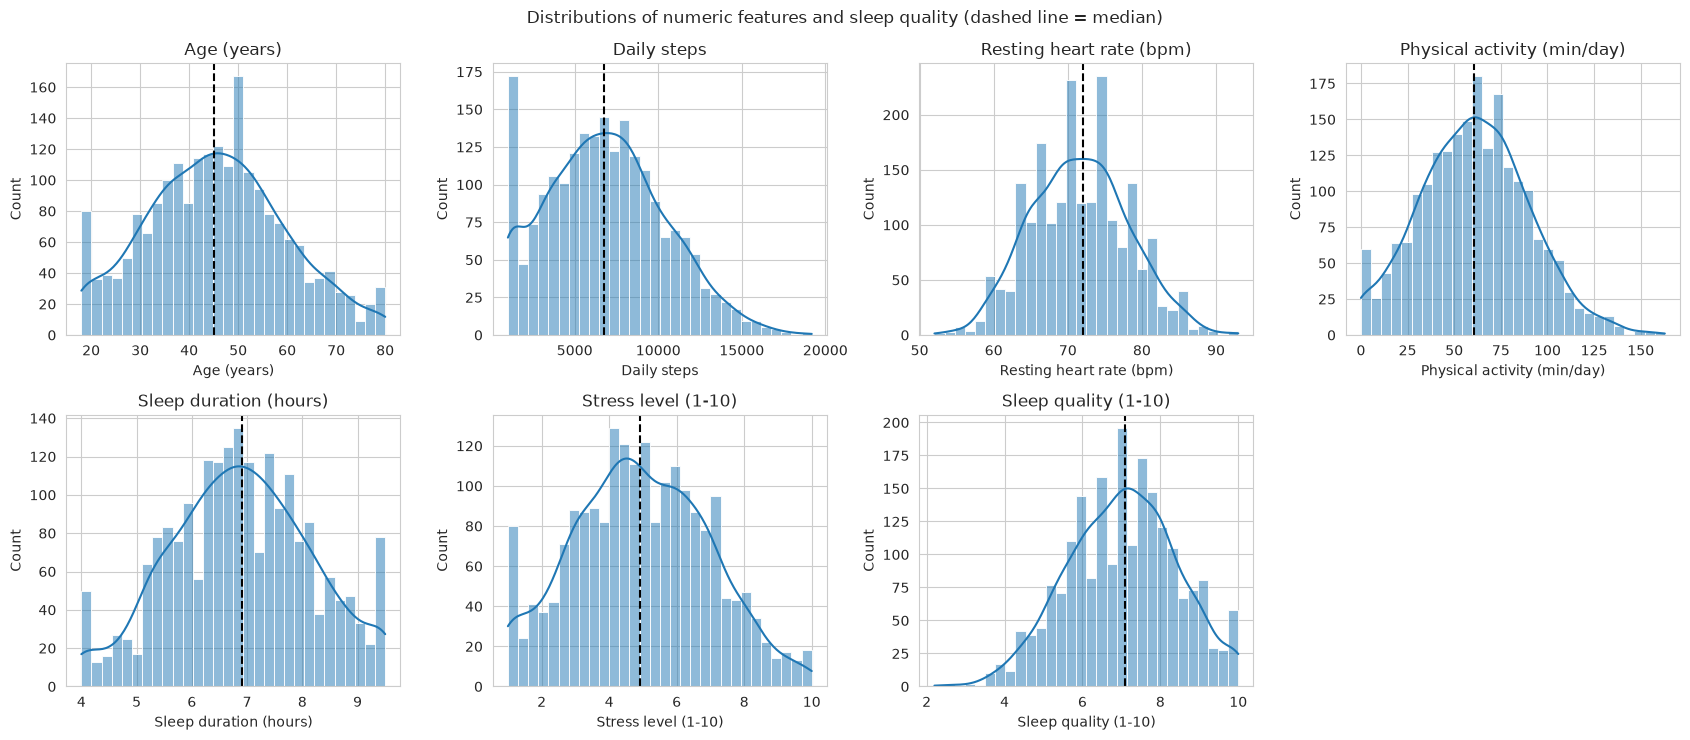

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.flatten()
for i in range(7):
    col = (num_cols + [TARGET])[i]
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i])
    axes[i].axvline(df[col].median(), color="black", linestyle="--")
    axes[i].set_title(labels[col])
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("Count")
axes[7].axis("off")
plt.suptitle("Distributions of numeric features and sleep quality (dashed line = median)")
plt.tight_layout()
plt.savefig(FIG + "/eda_03_numeric_distributions.png")
plt.show()

Figure: The output demonstrates a set of histograms representing numeric features and sleep quality score. The dashed line intersecting the distribution indicates the median. The mean score of sleep quality is approximately 7.04

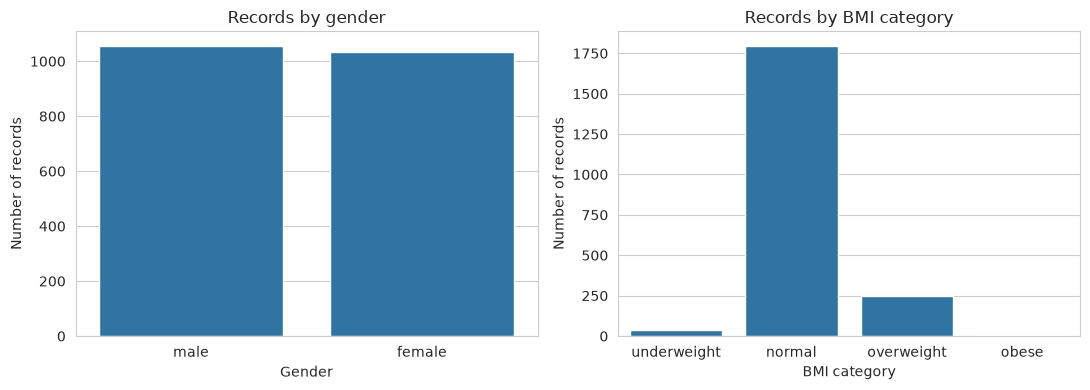

gender
male      1056
female    1035
Name: count, dtype: int64
bmi_category
normal         1796
overweight      250
underweight      39
obese             6
Name: count, dtype: int64


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="gender", data=df, ax=axes[0])
axes[0].set_title("Records by gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of records")
sns.countplot(x="bmi_category", data=df, ax=axes[1], order=["underweight", "normal", "overweight", "obese"])
axes[1].set_title("Records by BMI category")
axes[1].set_xlabel("BMI category")
axes[1].set_ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIG + "/eda_04_categorical_counts.png")
plt.show()
print(df["gender"].value_counts())
print(df["bmi_category"].value_counts())

Figure caption: Number of genders and by BMI category. Gender prominent in the dataset is balanced while majority of records fall roughly within the normal BMI with only 6 being obese. 

5. Correlation Heatmap

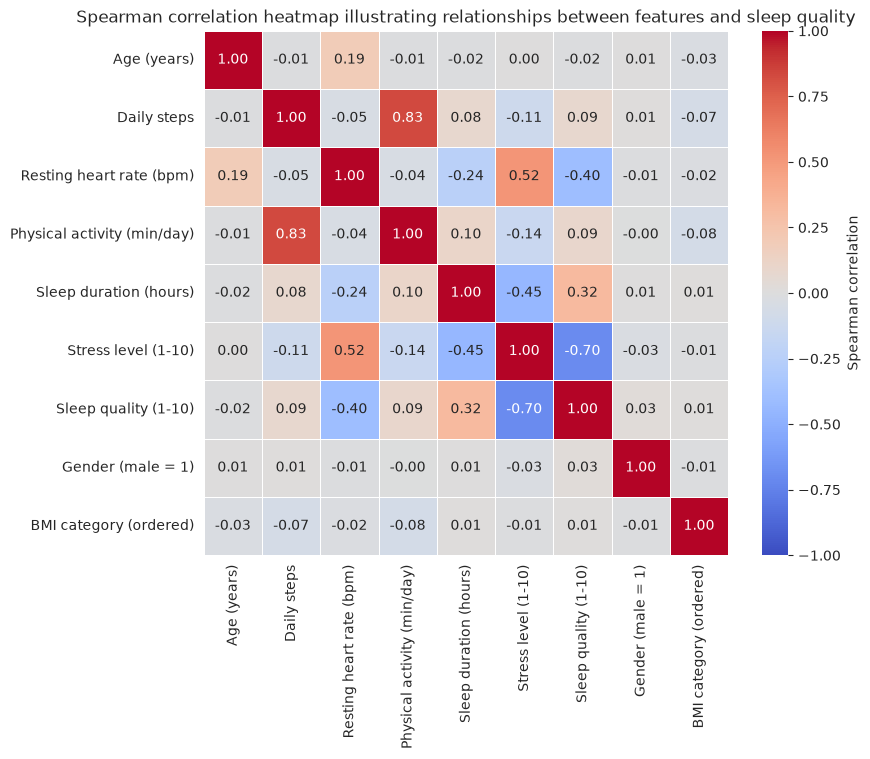

In [13]:
corr_data= df[num_cols + [TARGET]].copy()
corr_data["gender_male"]= (df["gender"]=="male").astype(int)
corr_data["bmi_order"]=df["bmi_category"].map({"underweight":0,"normal": 1,"overweight":2,"obese":3})

corr= corr_data.corr(method="spearman")
corr_display= corr.rename(index=labels, columns=labels)

plt.figure(figsize=(9,7.5))
sns.heatmap(corr_display, annot=True, fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,cbar_kws={"label": "Spearman correlation"}, square=True, linewidths=0.5)
plt.title("Spearman correlation heatmap illustrating relationships between features and sleep quality")
plt.tight_layout()
plt.savefig(FIG + "/eda_05_correlation_heatmap.png")
plt.show()


In [14]:
print("Spearman correlation with sleep quality: ")
print(corr[TARGET].drop(TARGET).sort_values().round(2))

Spearman correlation with sleep quality: 
stress_level              -0.70
heart_rate                -0.40
age                       -0.02
bmi_order                  0.01
gender_male                0.03
daily_steps                0.09
physical_activity_level    0.09
sleep_duration             0.32
Name: quality_of_sleep, dtype: float64


Spearman correlation between the features and the sleep-quality score (gender coded male = 1, BMI category ordered from underweight to obese). Stress level has the strongest link with sleep quality (negative), followed by heart rate (negative) and sleep duration (positive). Daily steps and physical activity are strongly related to each other (0.83).

6. Assessing Sleep Quality against every other feature 

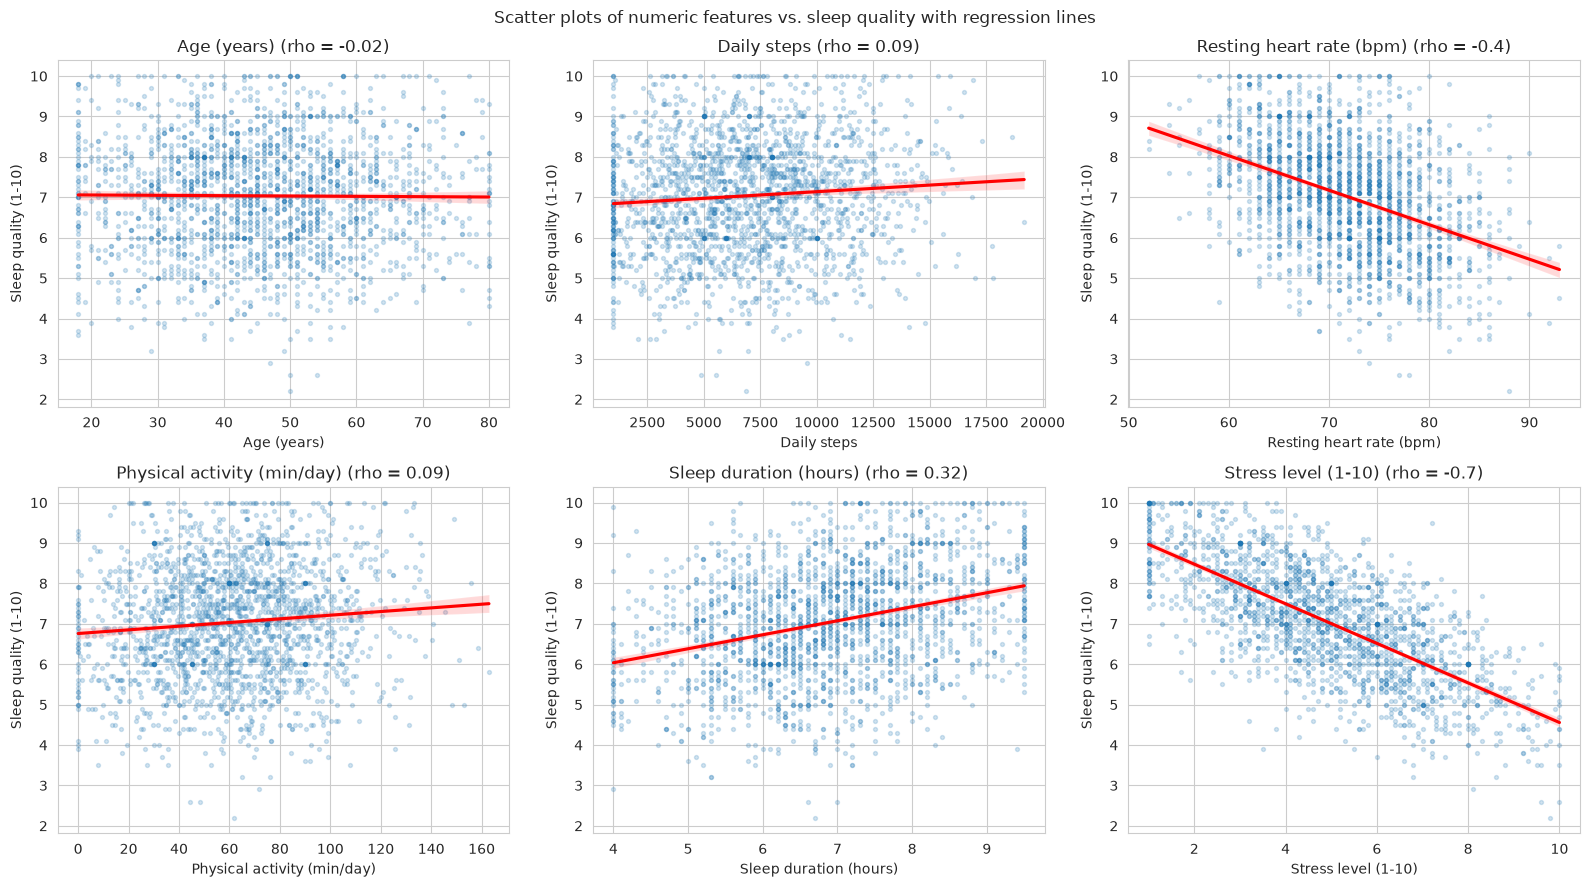

In [15]:
fig, axes = plt.subplots(2,3, figsize=(16,9))
axes=axes.flatten()
for i in range(6):
    col = num_cols[i] # Retrieves column name for the current iteration 
    sns.regplot(x=col, y=TARGET, data=df, ax=axes[i], scatter_kws={"s":8,"alpha": 0.2}, line_kws={"color":"red"})
    # In seaborn, the parameter scatter_kws controls the size andtransparency of the scatter points while line_kws defines the color of the regression line
    r = round(df[col].corr(df[TARGET],method="spearman"),2)
    # r contains the Spearman correlation coefficient between the current column and the target variable, and the final value is rounded to two decimals places for better readability
    axes[i].set_title(labels[col] + " (rho = " + str(r) + ")")
    axes[i].set_xlabel(labels[col])
    axes[i].set_ylabel("Sleep quality (1-10)")
# suptitle() is used to set a title for the entire figure
plt.suptitle("Scatter plots of numeric features vs. sleep quality with regression lines")
plt.tight_layout()
plt.savefig(FIG + "/eda_06_scatterplots_regression.png")
plt.show()


Figure caption: Demonstrates sleep quality score against each numeric feature, with a fitted trend line visualized in red. Sleep quality evidently drops as stress levels and heart rate spike and similarly, is improved with more stable sleep. However, factors such as age, daily steps, and activity virtually show no correlation. 

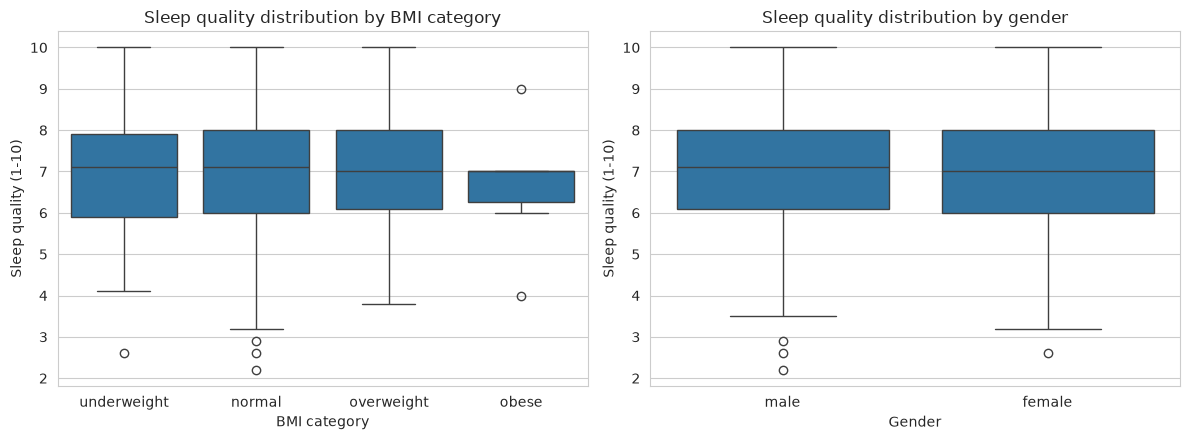

bmi_category
normal         7.03
obese          6.67
overweight     7.10
underweight    6.86
Name: quality_of_sleep, dtype: float64
gender
female    7.00
male      7.07
Name: quality_of_sleep, dtype: float64


In [16]:
fig, axes=plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x="bmi_category", y=TARGET, data=df, ax=axes[0], order=["underweight", "normal", "overweight", "obese"])
axes[0].set_title("Sleep quality distribution by BMI category")
axes[0].set_xlabel("BMI category")
axes[0].set_ylabel("Sleep quality (1-10)")

sns.boxplot(x="gender", y=TARGET, data=df, ax=axes[1])
axes[1].set_title("Sleep quality distribution by gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Sleep quality (1-10)")

plt.tight_layout()
plt.savefig(FIG + "/eda_07_boxplots_categorical.png") # Save the figure to a file in the specified directory with the given filename
plt.show()

print(df.groupby("bmi_category")[TARGET].mean().round(2))
# Computes the mean sleep quality for each BMI category 
print(df.groupby("gender")[TARGET].mean().round(2))
# Computes the mean sleep quality for each gender


Figure caption: The displayed boxplots demonstrate Sleep-quality score by BMI category and gender respectively. The groups yield similar medians, so neither feature separates sleep quality on its own **

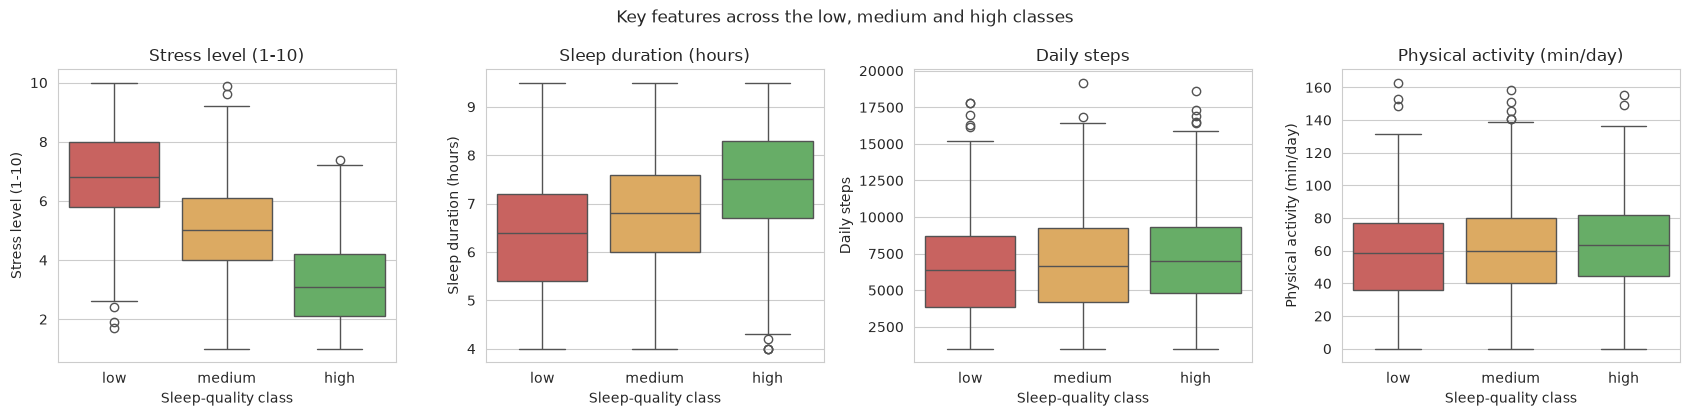

,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level
sleep_quality_class,,,,,,
low,46.0,6360.0,75.0,58.5,6.4,6.8
medium,46.0,6683.0,72.0,59.8,6.8,5.0
high,44.0,7000.0,68.0,63.6,7.5,3.1


In [17]:
key_cols=["stress_level", "sleep_duration", "daily_steps", "physical_activity_level"]
fig, axes= plt.subplots(1,4, figsize=(17,4.2))
for i in range(4):
    sns.boxplot(x=CLASS, y=key_cols[i], data=df, ax=axes[i], order=class_order,
                hue=CLASS, hue_order=class_order, palette=class_colors, legend=False)
    axes[i].set_title(labels[key_cols[i]])
    axes[i].set_xlabel("Sleep-quality class")
    axes[i].set_ylabel(labels[key_cols[i]])
plt.suptitle("Key features across the low, medium and high classes")
plt.tight_layout()
plt.savefig(FIG + "/eda_08_features_by_class.png")
plt.show()
df.groupby(CLASS)[num_cols].median().loc[class_order].round(1)

Figure caption: The displayed box plots outputs stress level, sleep duration, physical activity and daily steps within each sleep-quality class. The median stress level falls from 6.8 (low) to 3.1 (high) and median sleep duration rises from 6.4 h to 7.5 h, while activity and steps illustrate a subtle, slight change. 

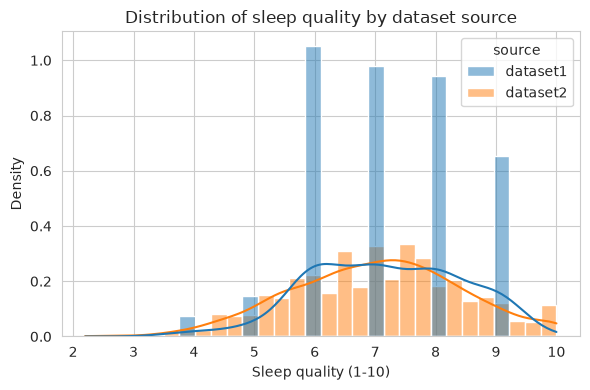

In [18]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x=TARGET, hue="source", stat="density", common_norm=False, kde=True, bins=30)
plt.title("Distribution of sleep quality by dataset source")
plt.xlabel("Sleep quality (1-10)")
plt.ylabel("Density") # Density is used to represent the distribution of sleep quality across different sources, allowing for a comparison of how sleep quality varies between datasets.
plt.tight_layout()
plt.savefig(FIG + "/eda_09_sleep_quality_by_source.png")
plt.show()
# Trend lines are used to visualize the distribution of sleep quality across different dataset sources, providing insights into potential differences in sleep quality patterns between the datasets.



Figure caption: Distribution of the sleep-quality score in each source dataset. Dataset 1 only has whole-number scores, while most dataset 2 scores are decimals; both centre roughly around 7

Synthesis of figure findings

- 2091 records in total, with 8 input features, classes: low 21.6%, medium 51.6%, high 26.9%.
- Stress level feature is regarded as the strongest single factor that deteriorates sleep quality, as indicated by the Spearman's statistic (rho=-0.70), followed by increases heart rate (rho=-0.40), and sleep duration (rho=+0.32).
- Age, gender, BMI category, daily steps, and physical activity each have virtually no direct correlation with sleep quality - given that their |rho| yields a value less than 0.1.
- Daily steps and physical activity are highly correlated with an rho yielding a value of 0.83, implying that they carry redundant information. 

# 2.2 Building and Training Random Forest Regression and Classification Models

### 2.2.1 Random Forest Regressor

Importing required packages/libraries

In [19]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor # used to build a random forest model for regression tasks-> predicting sleep quality from ranges spanning 0-10
from sklearn.model_selection import GridSearchCV # refine the model's parameters through exhaustive search over specified values to optimize model performance and improve its predictive accuracy
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score # evaluates performance of RF regressors 

Loading Processed Data

In [20]:

X_train = pd.read_csv("../data/processed/X_train_processed.csv")
X_test = pd.read_csv("../data/processed/X_test_processed.csv")
y_train = pd.read_csv("../data/processed/y_reg_train.csv")["quality_of_sleep"]
y_test = pd.read_csv("../data/processed/y_reg_test.csv")["quality_of_sleep"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
X_train.head()


X_train shape: (1672, 11)
X_test shape: (419, 11)


,age,daily_steps,heart_rate,physical_activity_level,sleep_duration,stress_level,gender_male,bmi_category_normal,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,0.513637,-0.570827,0.049705,-1.436283,-1.206634,-0.881408,0.0,1.0,0.0,0.0,0.0
1,2.213252,0.442141,0.049705,-0.170597,-1.129014,0.884365,0.0,1.0,0.0,0.0,0.0
2,1.009358,0.824692,2.196356,0.901960,-2.215690,1.994280,1.0,1.0,0.0,0.0,0.0
3,-0.477805,1.447469,0.049705,2.367673,0.268141,0.178056,0.0,1.0,0.0,0.0,0.0
4,-0.123718,0.125800,1.123030,0.463971,0.966718,0.379859,0.0,1.0,0.0,0.0,0.0


Train a forest using default settings parameters to determine baseline performance and further tune parameters to optimize model performance 

In [21]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
print("Training R^2:", round(rf.score(X_train, y_train), 3))
print("Testing R^2:", round(rf.score(X_test, y_test), 3))
# .score() returns R^2 (Square Root) statistically measuring how well the model's train and test data fit the actual data -> higher R^2 indicates better model performance
# Why? Because higher variance means it captures underlying patterns better, leading to accurate predictions and generalization to unseen data

Training R^2: 0.923
Testing R^2: 0.504


Results indicate an overfitting trend, where the regressor was capable of accurately predicting its training data. However, its performance drastically shrinked when feeding it with unseen data, demonstrating how it lacks strong generalization property. This suggests that the model merely memorized given training sets rather than capturing underlying patterns, and so it requires further parameter tuning using the GridSearchCV technique that limits the depth of the trees grown. 

Tuning RF regressor using GridSearchCV 

In [22]:
# Define the grid search parameters 
param_grid = {
    "n_estimators": [100,300], # Number of trees in the forest - 100 is often the ideal starting point balancing between model performance and computational efficiency while 300 trees provides robust model performance at the cost of more computational time
    "max_depth":[4,6,8,10,None], # controls the depth of the tree - prevents overfitting and allow generalization to unseen data by limiting complexity and capture essential patterns
    "min_samples_leaf":[1,5,10] 
}
grid = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring="r2", return_train_score=True, n_jobs=-1) # n_jobs=-1 utilizes all available CPU cores to speed up exhaustive search process
grid.fit(X_train, y_train)
print("Best parameter settings: ", grid.best_params_)
print("Best CV R2: ", round(grid.best_score_, 3))


Best parameter settings:  {'max_depth': 6, 'min_samples_leaf': 10, 'n_estimators': 100}
Best CV R2:  0.469


Model overfitting check and its plot to gain a visual intuition


In [23]:
results = pd.DataFrame(grid.cv_results_).sort_values(by="mean_test_score", ascending=False)
results = results[["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "mean_test_score", "mean_train_score"]] # select relevant columns for analysis and comparison of model performance across different combinations
results["gap"]= results["mean_train_score"] - results["mean_test_score"] # Derive a new column, gap, to quantify differences in training and testing performance which help observe potential overfitting/underfitting issues and guide further model tunes
results.round(3).head(10)

,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_test_score,mean_train_score,gap
10,100,6,10,0.469,0.590,0.121
11,300,6,10,0.468,0.590,0.122
28,100,None,10,0.467,0.640,0.172
9,300,6,5,0.467,0.613,0.146
22,100,10,10,0.467,0.638,0.171
0,100,4,1,0.467,0.530,0.063
6,100,6,1,0.467,0.629,0.162
1,300,4,1,0.467,0.530,0.063
16,100,8,10,0.467,0.628,0.160
2,100,4,5,0.467,0.527,0.060


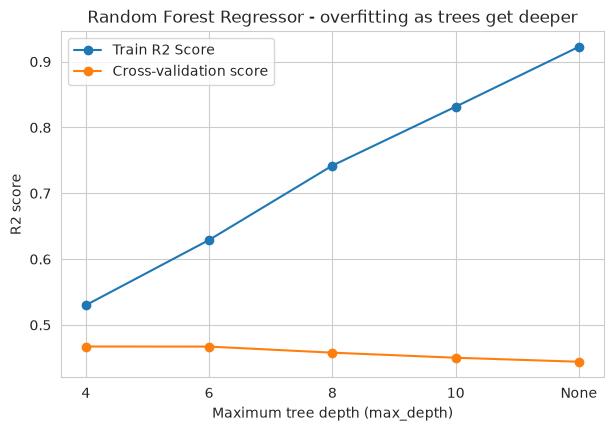

In [24]:
# Visual intuition of how overfitting increases as tree depth grows 

deep = results[(results["param_n_estimators"]==100) & (results["param_min_samples_leaf"]==1)]
tree_depth_labels= ["4","6","8","10","None"]

plt.figure(figsize=(7, 4.5))
plt.plot(tree_depth_labels, deep["mean_train_score"], marker="o", label="Train R2 Score")
plt.plot(tree_depth_labels, deep["mean_test_score"], marker="o", label="Cross-validation score")
plt.title("Random Forest Regressor - overfitting as trees get deeper")
plt.xlabel("Maximum tree depth (max_depth)")
plt.ylabel("R2 score")
plt.legend()
plt.savefig("../figures/rf_01_regressor_overfitting.png")
plt.show()


The line plot illustrates how overfitting increases as tree depth grows. The training R2 score increases with deeper trees, while cross validation score decreases, indicating model fits the data overly well and fails to generalize. This represents a classic case of overfitting, where the model captures noise and specific patterns in the training data that dont generalize to unseen data, increasing the need for further parameter tuning.

Test set evaluation using R^2, MAE, RMSE statistical metrics

In [25]:
# Testing optimal parameters on new test set to evaluate model performance 
best_rf = grid.best_estimator_
y_pred = best_rf.predict(X_test)

# Evaluate the tuned Random Forest Regressor using three metrics
# Each one grades the predictions differently, so together they give a fuller picture.

# Train R2: how well the model fits the people it learned from (the "practice" score).
# Compare it with Test R2 below: a large gap would mean overfitting (memorising).
print("Train R2:", round(best_rf.score(X_train, y_train), 3))

# Test R2: how much better the model is than guessing the average score for everyone,
# measured on unseen people. 0 = no better than guessing, 1 = perfect predictions.
print("Test R2:", round(r2_score(y_test, y_pred), 3))

# Test MAE (Mean Absolute Error): on average, how many points (out of 10)
# the predictions are away from the real sleep-quality scores.
print("Test MAE:", round(mean_absolute_error(y_test, y_pred), 3))

# Test RMSE (Root Mean Squared Error): like MAE, but squares each error first,
# so big misses count more. "** 0.5" takes the square root to return to score points.
# If RMSE is much larger than MAE, the model makes some large mistakes.
print("Test RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 3))

Train R2: 0.582
Test R2: 0.533
Test MAE: 0.725
Test RMSE: 0.922


Constructing predicted vs. actual plots pertaining to sleep quality after parameter tuning

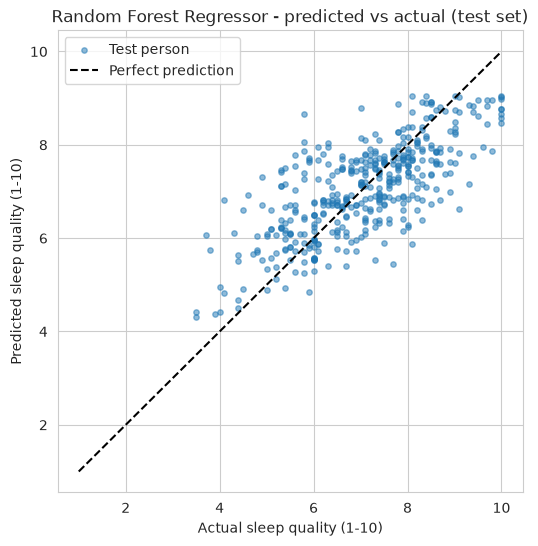

In [26]:
# Compare each test person's real sleep score with the model's prediction.
# Points on the dashed line are perfect predictions; distance from the line = error.
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=15, alpha=0.5, label="Test person")
plt.plot([1, 10],[1, 10], "k--", label="Perfect prediction") # k-- = keyword for black dashed line
plt.title("Random Forest Regressor - predicted vs actual (test set)")
plt.xlabel("Actual sleep quality (1-10)")
plt.ylabel("Predicted sleep quality (1-10)")
plt.legend()
plt.savefig("../figures/rf_02_regressor_pred_vs_actual.png")
plt.show()

Feature Importance -> Lifestyle factors the RF regressor relied on the most

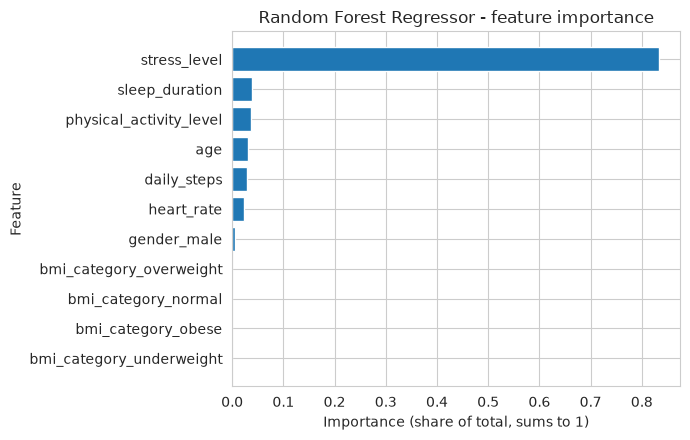

In [27]:
# Feature importance: how much each feature helped the forest make its predictions.
# The values add up to 1, so each one is that feature's share of the total.
importance = pd.Series(best_rf.feature_importances_, index=X_train.columns)
importance = importance.sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(importance.index, importance.values) # barh() creates a horizontal bar plot where the y-axis represents feature names and the x-axis represents its corresponding values- stacks data through bottom up approach - enhances interpretability of feature importance as it helps easily identify the dominating feature that strongly impacts the target
plt.title("Random Forest Regressor - feature importance")
plt.xlabel("Importance (share of total, sums to 1)")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("../figures/rf_03_regressor_feature_importance.png") 
plt.show()




Saving all regressor scores

In [28]:
# Collect the regressor's key scores into a one-row table and save it,
# so the team can compare it with Hams's baseline models in the report.
rf_reg_results = pd.DataFrame([{
    "model": "Random Forest Regressor (tuned)",
    "cv_r2": grid.best_score_,                                         # average R2 across the 5 CV folds
    "cv_r2_std": grid.cv_results_["std_test_score"][grid.best_index_], # how much the 5 fold scores varied
    "train_r2": best_rf.score(X_train, y_train),
    "test_r2": r2_score(y_test, y_pred),
    "test_mae": mean_absolute_error(y_test, y_pred),
    "test_rmse": mean_squared_error(y_test, y_pred) ** 0.5
}]).round(3)

rf_reg_results.to_csv("../results/rf_regressor_results.csv", index=False)
rf_reg_results

,model,cv_r2,cv_r2_std,train_r2,test_r2,test_mae,test_rmse
0,Random Forest Regressor (tuned),0.469,0.049,0.582,0.533,0.725,0.922


In [29]:
# Put the Random Forest next to Hams's regression baselines in one table for better readability 
baseline = pd.read_csv("../results/baseline_results.csv")
reg_comparison = pd.concat([baseline, rf_reg_results])
reg_comparison = reg_comparison.dropna(subset=["test_r2"])     # keep only regression models (classifiers have no R2)
reg_comparison[["model", "cv_r2", "test_r2", "test_mae", "test_rmse"]]

print(len(baseline)) # 6
print(len(reg_comparison)) # 4
# original baseline table remains unchanged, while reg_comparisons includes new RF regressor results with only regression models and their corresponding metrics 



6
4


### Synthesizing Random Forest Regressor Results

- **Tuning:** GridSearchCV (5-fold CV, 30 combinations) selected `max_depth=6`, `min_samples_leaf=10`, `n_estimators=100` (CV R² = 0.469).
- **Overfitting:** the default forest scored R² 0.923 on training data but only 0.504 on the test set. Limiting tree depth and leaf size reduced the train–test gap from 0.42 to 0.05.
- **Test performance:** R² = 0.533, MAE = 0.725, RMSE = 0.922. Predictions are off by about 0.7 points on the 1–10 scale on average.
- **Comparison:** performance is close to Linear Regression (test R² 0.545), suggesting the relationship between lifestyle factors and sleep quality is largely linear in this dataset.
- **Feature importance:** stress level dominates (≈0.83 of total importance); sleep duration, activity, age, steps and heart rate contribute little extra, and BMI and gender minimally contribute.
- **Limitation:** the model pulls extreme scores toward the average, overestimating low sleep quality and underestimating high sleep quality.

### 2.2.2 Random Forest Classifier

Importing required packages

In [30]:
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay


Load processed data 

In [31]:
y_clf_train = pd.read_csv("../data/processed/y_clf_train.csv")["sleep_quality_class"] 
y_clf_test = pd.read_csv("../data/processed/y_clf_test.csv")["sleep_quality_class"]
#  ["sleep_quality_class"] is written in order to retrieve the target feature as the labels for the output training and testing data
class_order = ["low","medium","high"]
print(y_clf_train.value_counts())



sleep_quality_class
medium    862
high      449
low       361
Name: count, dtype: int64


Developing the default forest model (unlimited trees)to observe potential overfitting patterns

In [32]:
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(X_train, y_clf_train)
train_accuracy= rf_clf.score(X_train, y_clf_train)
test_accuracy= rf_clf.score(X_test, y_clf_test)
test_f1= f1_score(y_clf_test, rf_clf.predict(X_test), average="macro")
print("Train accuracy: ", round(train_accuracy, 3))
print("Test accuracy: ", round(test_accuracy, 3))
print("Test macro F1: ", round(test_f1,3))

Train accuracy:  1.0
Test accuracy:  0.642
Test macro F1:  0.602


In [33]:
param_grid_classif={
    "n_estimators": [300],
    "max_depth": [4,6,8,10,None],
    "min_samples_leaf":[1,5,10],
    "class_weight":[None,"balanced"]
}

grid_classif = GridSearchCV(RandomForestClassifier(random_state=42),param_grid_classif,cv=5, scoring="f1_macro" \
,return_train_score=True, n_jobs=-1)
grid_classif.fit(X_train, y_clf_train)
print("Best settings:", grid_classif.best_params_)
print("Best CV macro F1:", round(grid_classif.best_score_,3))


Best settings: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}
Best CV macro F1: 0.59


Overfitting by depth

rows found: 5


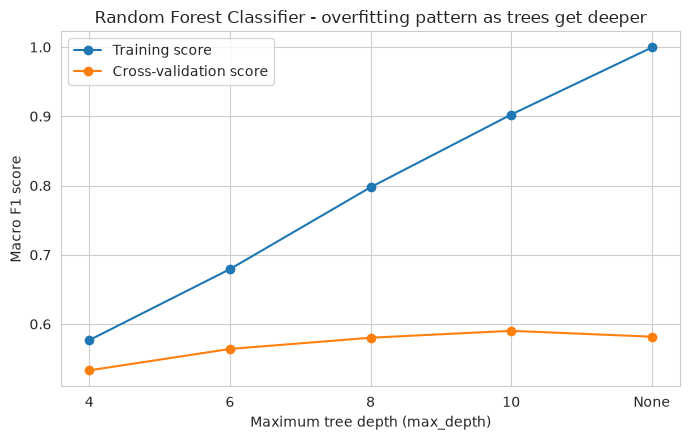

,param_max_depth,mean_train_score,mean_test_score,gap
15,4,0.577,0.533,0.044
18,6,0.679,0.564,0.115
21,8,0.798,0.580,0.217
24,10,0.903,0.590,0.312
27,None,0.999,0.582,0.418


In [34]:
results_classif=pd.DataFrame(grid_classif.cv_results_)
results_classif["gap"]=results_classif["mean_train_score"]-results_classif["mean_test_score"]

deep_classif=results_classif[(results_classif["param_class_weight"]=="balanced") &
(results_classif["param_n_estimators"]==300)&
(results_classif["param_min_samples_leaf"]==1)].sort_index()

print("rows found:", len(deep_classif))

depth_labels = ["4","6","8","10","None"]
plt.figure(figsize=(7,4.5))
plt.plot(depth_labels, deep_classif["mean_train_score"], "o-", label="Training score")
plt.plot(depth_labels, deep_classif["mean_test_score"], "o-", label="Cross-validation score")
plt.title("Random Forest Classifier - overfitting pattern as trees get deeper")
plt.xlabel("Maximum tree depth (max_depth)")
plt.ylabel("Macro F1 score")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/rf_04_classifier_overfitting.png")
plt.show()

deep_classif[["param_max_depth", "mean_train_score", "mean_test_score", "gap"]].round(3)



Test set evaluation and Confusion Matrix

Test accuracy: 0.609
Test macro F1: 0.609
              precision    recall  f1-score   support

         low      0.542     0.644     0.589        90
      medium      0.691     0.528     0.598       216
        high      0.565     0.735     0.638       113

    accuracy                          0.609       419
   macro avg      0.599     0.636     0.609       419
weighted avg      0.625     0.609     0.607       419



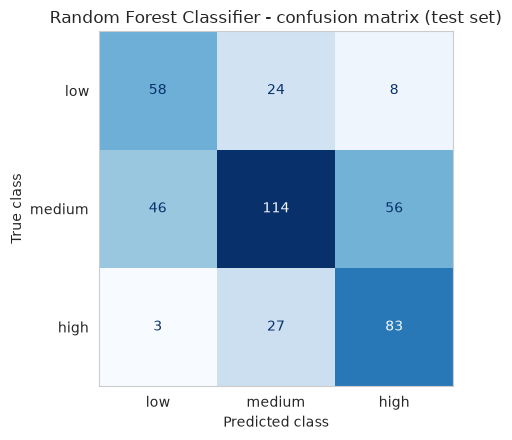

In [35]:
best_classif = grid_classif.best_estimator_     # provides chosen settings, retrained on all training data
y_clf_pred = best_classif.predict(X_test)       # predicted class (low/medium/high) for each testing data 

print("Test accuracy:", round(accuracy_score(y_clf_test, y_clf_pred), 3))
print("Test macro F1:", round(f1_score(y_clf_test, y_clf_pred, average="macro"), 3)) # average = "macro" treats each class fairly by scoring each individually then averages them
# Precision, recall and F1 for each class separately; digits=3 shows 3 decimals
print(classification_report(y_clf_test, y_clf_pred, labels=class_order, digits=3))

# Confusion matrix: rows = true class, columns = predicted class.
# Diagonal cells are correct predictions; off-diagonal cells show which classes are misclassified 
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_clf_test, y_clf_pred, labels=class_order,
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Random Forest Classifier - confusion matrix (test set)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.grid(False)    # removes grid for better readability 
plt.tight_layout()
plt.savefig("../figures/rf_05_classifier_confusion_matrix.png")
plt.show()

Feature importance

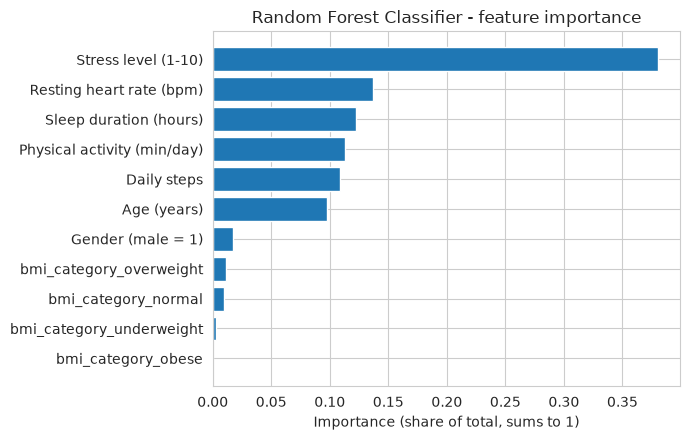

Stress level (1-10)            0.380
Resting heart rate (bpm)       0.137
Sleep duration (hours)         0.123
Physical activity (min/day)    0.113
Daily steps                    0.108
Age (years)                    0.098
Gender (male = 1)              0.017
bmi_category_overweight        0.012
bmi_category_normal            0.009
bmi_category_underweight       0.003
bmi_category_obese             0.000
dtype: float64

In [36]:
importance_classif = pd.Series(best_classif.feature_importances_, index=X_train.columns)
importance_classif = importance_classif.sort_values()          # ascending, so barh puts the biggest bar on top
importance_classif = importance_classif.rename(index=labels)   # readable names, used for display purposes only

plt.figure(figsize=(7, 4.5))
plt.barh(importance_classif.index, importance_classif.values)
plt.title("Random Forest Classifier - feature importance")
plt.xlabel("Importance (share of total, sums to 1)")
plt.tight_layout()
plt.savefig("../figures/rf_06_classifier_feature_importance.png")
plt.show()

importance_classif.sort_values(ascending=False).round(3)   # display it as a table

Save results and compare model outcomes

In [ ]:
# Saving the RF classifier scores as a one-row table, saved next to the regressor's results for easy comparison 
rf_clf_results = pd.DataFrame([{
    "model": "Random Forest Classifier (tuned)",
    "cv_f1_macro": grid_classif.best_score_,
    "test_accuracy": accuracy_score(y_clf_test, y_clf_pred),
    "test_f1_macro": f1_score(y_clf_test, y_clf_pred, average="macro")
}]).round(3)
rf_clf_results.to_csv("../results/rf_classifier_results.csv", index=False)

# Load the saved regressor scores instead of re-running the regressor's grid search
rf_reg_results = pd.read_csv("../results/rf_regressor_results.csv")
baseline = pd.read_csv("../results/baseline_results.csv")

# One table with every model (Hams's baselines + both forests) for the report
all_models = pd.concat([baseline, rf_reg_results, rf_clf_results])
all_models.to_csv("../results/model_comparison.csv", index=False)

# Classifier rows only: regression models have no accuracy, so their test_accuracy is NaN
clf_comparison = all_models.dropna(subset=["test_accuracy"]) # drops regressor rows whose test_accuracy is NaN since it doesnt use it as an evaluation metric
clf_comparison[["model", "cv_f1_macro", "test_accuracy", "test_f1_macro"]]

,model,cv_f1_macro,test_accuracy,test_f1_macro
3,Majority class (reference),0.227,0.516,0.227
4,Logistic Regression (default),0.570,0.666,0.625
5,"Logistic Regression (tuned: C=1, class_weight=...",0.570,0.666,0.625
0,Random Forest Classifier (tuned),0.590,0.609,0.609
